# AVP neuron with CAN DAP ($\mu=1$): time traces and two-parameter bifurcations (fast version)
Everything here is plain numpy/scipy, with no PyDSTool or PyCont. The previous notebook was slow because PyDSTool's Python target evaluated about 30 nested string-defined functions on every right-hand-side call (and PyCont inherits that cost). Here the model is written once as ordinary code, and two cheap tools replace continuation software:

* **Time traces:** scipy LSODA with a spike event and the $D$ jump. Budget: about 12 s of compute per 40 s of simulated time on my machine, so the default 120 s run takes roughly 40 s.
* **Equilibria, folds and Hopf points:** for frozen $(C_i, D)$ the equilibria of the six fast states are the zeros of one scalar function $F(V;C_i,D)=I_{app}-I_{\rm tot}$ on the steady-state manifold. I draw that zero set as a curve in the $(C_i,V)$ plane, then compute the eigenvalues of the $6\times6$ Jacobian along it. Folds (LP) are turning points in $C_i$; Hopf points (H) are where a complex pair crosses $\mathrm{Re}=0$. This takes about 0.2 s per value of $D$.
* **Limit-cycle branches:** the stable cycle is followed in $C_i$ by integrating the frozen fast subsystem with warm starts, recording $V_{\max}$, $V_{\min}$ and the period $T$. Unstable cycles are not traced. A period $T\to\infty$ at a fold marks a SNIC (saddle-node on an invariant circle); $T\to\infty$ at a Hopf-free end of the branch with no equilibrium there would indicate a homoclinic instead.

In [1]:
import math, os, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

np.seterr(all='ignore'); warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.alpha': 0.2, 'grid.linewidth': 0.5, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 10, 'axes.labelsize': 10,
    'legend.frameon': False, 'legend.fontsize': 8.5, 'lines.solid_capstyle': 'round',
})
COL = dict(V='#1b2a49', Ci='#2a7f62', D='#b5482a', f='#6a4c93', cycle='#1f6fb4', fold='#c0392b', hopf='#1f3fbf', end='#2e8b57')

# ------------------------------ settings ------------------------------
MU        = 1.0            # 0 = K-leak DAP, 1 = CAN DAP
IAPP      = 2.0            # applied current (report baseline 1.28 is quiescent for mu = 1)
T_MS      = 120_000.0      # time-trace length (ms)
D_SLICES  = (0.0, 7.5, 12.5)  # values of D at which the one-parameter diagrams are drawn
D_MAX     = 30.0           # range of D in the two-parameter diagram
CI_RANGE  = (60.0, 1500.0) # Ci range scanned for equilibria


## 1. Model
The leak with the homotopy is
$$I_{\rm leak} = g_{\rm NaL}(V-E_{\rm Na}) + g_{\rm KL}\big(1-(1-\mu)f\big)(V-E_{\rm K}) + \mu\,g_{\rm CAN}(\alpha+f)(V-E_{\rm CAN}),\qquad f=\tanh\!\Big(\tfrac{C_i-C_r-\phi D}{k_p}\Big)q(V).$$
`make_model` is written once and instantiated with `math` functions (fast, scalar, for the ODE solver) and with numpy functions (vectorised, for the bifurcation grids), so the two cannot disagree.

In [3]:
P = dict(Cm=1.0, gNa=14.0, gCa=0.1, gDR=14.0, gA=14.0, gAHP=0.18, gC=1.0, ENa=50.0, EK=-96.0, Co=4.0e6,
         VmNa=-38.0, kmNa=4.0, VhNa=-45.0, khNa=-2.0, VmK=-2.0, kmK=11.0, VmA=-45.0, kmA=11.0, VhA=-80.0, khA=-6.5,
         VmCa=-10.0, kmCa=7.0, Cr=113.0, tau_i=2330.0, tau_BK=1.0, tau_SK=656.0, a_i=0.9, a_BK=100.0, a_SK=1.6,
         kp=55.0, kq=7.0, Vq=-70.0, phi=20.0, D0=0.001, dD=0.025, tauD=4900.0, Iapp=IAPP,
         gNaL0=0.01826, gKL=0.06655, ECAN=-35.0, alpha=0.6)

def make_model(exp, log, tanh, p):
    g = p.__getitem__
    Cm,gNa,gCa,gDR,gA,gAHP,gC = g('Cm'),g('gNa'),g('gCa'),g('gDR'),g('gA'),g('gAHP'),g('gC')
    ENa,EK,Co,Cr = g('ENa'),g('EK'),g('Co'),g('Cr')
    gNaL,gKL,gCAN,ECAN,alpha,mu = g('gNaL'),g('gKL'),g('gCAN'),g('ECAN'),g('alpha'),g('mu')
    kp,kq,Vq,phi = g('kp'),g('kq'),g('Vq'),g('phi')
    VmNa,kmNa,VhNa,khNa,VmK,kmK = g('VmNa'),g('kmNa'),g('VhNa'),g('khNa'),g('VmK'),g('kmK')
    VmA,kmA,VhA,khA,VmCa,kmCa = g('VmA'),g('kmA'),g('VhA'),g('khA'),g('VmCa'),g('kmCa')
    a_BK,a_SK,tau_BK,tau_SK = g('a_BK'),g('a_SK'),g('tau_BK'),g('tau_SK')
    ln10 = math.log(10.0)
    def boltz(V, Vm, k): return 1.0/(1.0+exp(-(V-Vm)/k))
    def ICa_(V, m, Ci): return gCa*m*m*(V-12.5*log(Co/Ci))
    def Itot(V, h, mK, mC, Cb, Cs, Ci, D):
        mNa = boltz(V, VmNa, kmNa); mA = boltz(V, VmA, kmA); hA = boltz(V, VhA, khA)
        mCb  = 1.0/(1.0+(470.0/Cb)**2.38)/(1.0+exp(-(V+140.0*log(Cb)/ln10-370.0)/7.4))
        mAHP = 1.0/(1.0+exp(-(1.12+2.508*0.5*log(((Cs-Cr)/1000.0)**2+1e-18)/ln10)))
        f = tanh((Ci-Cr-phi*D)/kp)*boltz(V, Vq, kq)
        Ileak = gNaL*(V-ENa)+gKL*(1.0-(1.0-mu)*f)*(V-EK)+mu*gCAN*(alpha+f)*(V-ECAN)
        return (gNa*mNa**3*h*(V-ENa)+gDR*mK**3*(V-EK)+gA*mA**4*hA*(V-EK)+gC*mCb*(V-EK)
                +gAHP*mAHP**2*(V-EK)+ICa_(V, mC, Ci)+Ileak)
    def rhs6(V, h, mK, mC, Cb, Cs, Ci, D, Iapp):
        """Fast subsystem (Ci, D frozen)."""
        ICa = ICa_(V, mC, Ci)
        tauh  = 0.075+20.0/((1.0+exp((V+1.0)/14.0))*(1.0+exp((V+30.0)/34.0)))
        taum  = 8.0/(exp((V+40.0)/19.0)+exp(-(V+40.0)/20.0))+1.8
        taumC = 1.0/(0.19*(V-19.88)/(exp((V-19.88)/10.0)-1.0)+0.046*exp(-V/20.73))
        return ((Iapp-Itot(V, h, mK, mC, Cb, Cs, Ci, D))/Cm, (boltz(V, VhNa, khNa)-h)/tauh,
                (boltz(V, VmK, kmK)-mK)/taum, (boltz(V, VmCa, kmCa)-mC)/taumC,
                -a_BK*ICa-(Cb-Cr)/tau_BK, -a_SK*ICa-(Cs-Cr)/tau_SK)
    def steady(V, Ci):
        """Gates and calcium pools at equilibrium for a given V."""
        m = boltz(V, VmCa, kmCa); ICa = ICa_(V, m, Ci)
        return (V, boltz(V, VhNa, khNa), boltz(V, VmK, kmK), m, Cr-a_BK*tau_BK*ICa, Cr-a_SK*tau_SK*ICa)
    def Fss(V, Ci, D, Iapp):
        """Iapp - total current on the steady-state manifold; zeros in V are the fast-subsystem equilibria."""
        return Iapp-Itot(*steady(V, Ci), Ci, D)
    return dict(rhs6=rhs6, steady=steady, Fss=Fss, Itot=Itot, boltz=boltz)

def calibrate(p, mu):
    """gCAN and gNaL(mu): match the DAP gain at V* = V_r and keep the resting conductance fixed."""
    q = dict(p); q.update(gNaL=q['gNaL0'], gCAN=0.0, mu=0.0)
    M = make_model(np.exp, np.log, np.tanh, q)
    def I_rest(V):                       # K-leak model, Iapp = 0, f = 0 (D chosen so that tanh arg = 0), steady state
        Ci = q['Cr']
        for _ in range(80):              # Ci_star: Ci - Cr + a_i tau_i ICa = 0
            m = M['boltz'](V, q['VmCa'], q['kmCa']); ICa = q['gCa']*m*m*(V-12.5*np.log(q['Co']/Ci))
            Ci = max(q['Cr'], q['Cr']-q['a_i']*q['tau_i']*ICa)
        return M['Itot'](*M['steady'](V, Ci), Ci, (Ci-q['Cr'])/q['phi'])
    Vr = brentq(I_rest, -95, -55)
    gCAN = q['gKL']*(Vr-q['EK'])/(q['ECAN']-Vr)
    gNaL = q['gNaL0']-mu*q['alpha']*gCAN*(q['ECAN']-Vr)/(q['ENa']-Vr)
    q.update(gCAN=gCAN, gNaL=gNaL, Vr=Vr, mu=mu)
    return q

q = calibrate(P, MU)
safe_exp = lambda x: math.exp(x if x < 700.0 else 700.0)
Ms = make_model(safe_exp, math.log, math.tanh, q)       # scalar version for the ODE solver
Mv = make_model(np.exp, np.log, np.tanh, q)             # vectorised version for bifurcation grids
print('mu = %.2f  Iapp = %.2f  V_r = %.2f mV  gCAN = %.5f  gNaL = %.5f  (alpha = %.2f)' % (q['mu'], q['Iapp'], q['Vr'], q['gCAN'], q['gNaL'], q['alpha']))

mu = 1.00  Iapp = 2.00  V_r = -64.75 mV  gCAN = 0.06990  gNaL = 0.00739  (alpha = 0.60)


## 2. Time traces (full 8-state system with the $D$ jump)
A spike is an upward crossing of $V=0$; then $D\leftarrow(1+\delta_D)D+\Delta_0$. LSODA is restarted after each spike.

simulated 120 s in 13 s wall time, 1161 spikes
{'n_spikes': 1161, 'n_bursts': 7, 'class': 'phasic', 'burst_dur_s': np.float64(4.405), 'silence_s': np.float64(13.155), 'Ci_plateau': np.float64(383.698), 'D_peak': np.float64(13.011), 'nu_Hz': np.float64(32.243)}
critical firing rate nu_c = 1/(dD*tauD) = 8.16 Hz


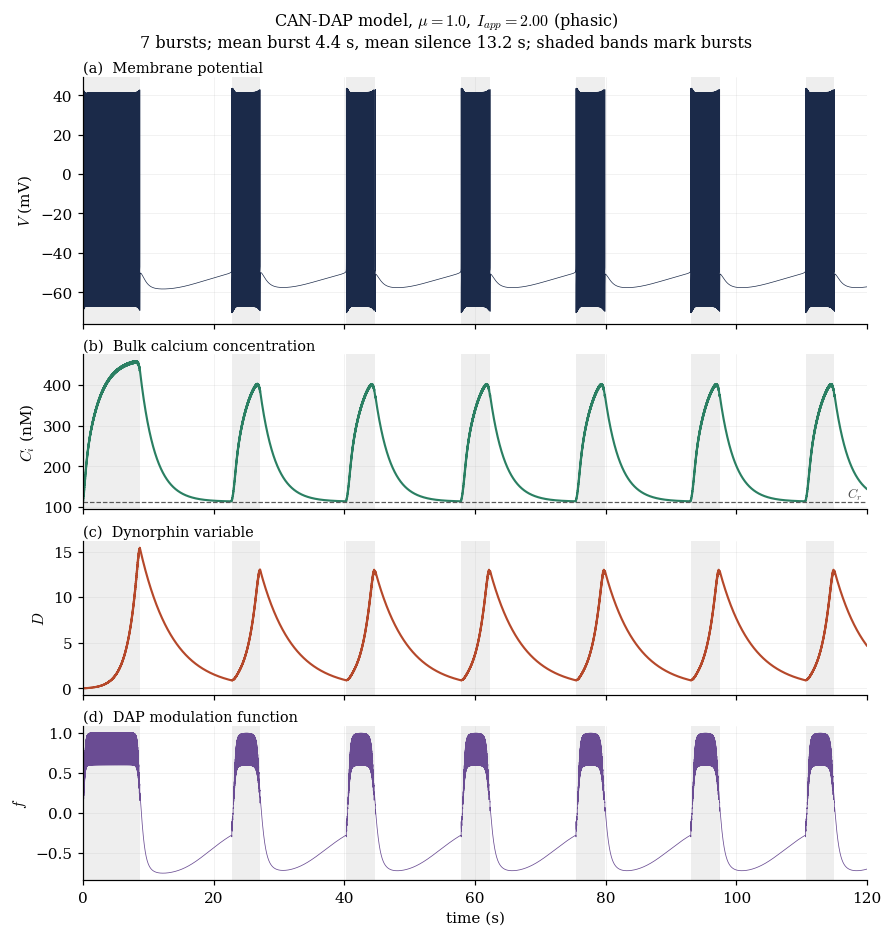

In [8]:
rhs6s = Ms['rhs6']
def rhs_full(t, x):
    V, h, mK, mC, Ci, Cb, Cs, D = x
    d = rhs6s(V, h, mK, mC, Cb, Cs, Ci, D, q['Iapp'])
    ICa = q['gCa']*mC*mC*(V-12.5*math.log(q['Co']/Ci))
    return [d[0], d[1], d[2], d[3], -q['a_i']*ICa-(Ci-q['Cr'])/q['tau_i'], d[4], d[5], -D/q['tauD']]

def simulate(T_ms, max_step=2.0):
    x = [-60.0, 0.9, 0.0, 0.0, q['Cr'], q['Cr'], q['Cr'], 0.0]; t = 0.0
    ev = lambda tt, z: z[0]
    ev.direction = 1; ev.terminal = True
    ts, ys, spk = [], [], []
    while t < T_ms:
        sol = solve_ivp(rhs_full, [t, T_ms], x, method='LSODA', events=ev, rtol=1e-6, atol=1e-8, max_step=max_step)
        ts.append(sol.t); ys.append(sol.y)
        if sol.status != 1: break
        t = sol.t_events[0][0]; x = list(sol.y_events[0][0]); x[7] = (1+q['dD'])*x[7]+q['D0']; x[0] += 1e-6; t += 1e-6; spk.append(t)
    Y = np.hstack(ys); r = dict(zip(['V', 'h', 'mK', 'mC', 'Ci', 'Cb', 'Cs', 'D'], Y)); r['t'] = np.concatenate(ts); r['spk'] = np.array(spk)
    r['f'] = np.tanh((r['Ci']-q['Cr']-q['phi']*r['D'])/q['kp'])/(1+np.exp(-(r['V']-q['Vq'])/q['kq']))
    return r

def burst_metrics(r, gap_ms=2000.0):
    spk, t = r['spk'], r['t']; out = dict(n_spikes=len(spk))
    if len(spk) < 5: out['class'] = 'quiescent'; return out
    isi = np.diff(spk); idx = np.where(isi > gap_ms)[0]
    starts = np.r_[spk[0], spk[idx+1]]; ends = np.r_[spk[idx], spk[-1]]; n = len(starts); out['n_bursts'] = n
    out['class'] = 'tonic' if n == 1 else ('phasic' if n >= 3 else 'other')
    if n < 2: return out
    ii = np.arange(1, n-1) if n >= 3 else np.arange(0, n-1)       # drop first (transient) and last (truncated) burst
    out['burst_dur_s'] = np.mean((ends-starts)[ii])/1000; out['silence_s'] = np.mean(starts[ii+1]-ends[ii])/1000
    Cpl, Dpk, nu = [], [], []
    for a in ii:
        m = (t >= starts[a]) & (t <= ends[a]); half = (t >= 0.5*(starts[a]+ends[a])) & (t <= ends[a])
        Cpl.append(np.median(r['Ci'][half])); Dpk.append(r['D'][m].max()); k = ((spk >= starts[a]) & (spk <= ends[a])).sum()
        nu.append(1000*(k-1)/(ends[a]-starts[a]))
    out.update(Ci_plateau=np.mean(Cpl), D_peak=np.mean(Dpk), nu_Hz=np.mean(nu)); return out

t0 = time.time(); R = simulate(T_MS)
print('simulated %.0f s in %.0f s wall time, %d spikes' % (T_MS/1000, time.time()-t0, len(R['spk'])))
MET = burst_metrics(R); print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in MET.items()})
print('critical firing rate nu_c = 1/(dD*tauD) = %.2f Hz' % (1000/(q['dD']*q['tauD'])))


BURST_GAP_MS = 2000.0     # an inter-spike interval longer than this separates two bursts

def burst_intervals(spk, gap_ms=BURST_GAP_MS):
    """(start, end) of each burst in seconds."""
    if len(spk) < 2: return np.empty((0, 2))
    idx = np.where(np.diff(spk) > gap_ms)[0]
    return np.c_[np.r_[spk[0], spk[idx+1]], np.r_[spk[idx], spk[-1]]] / 1000.0

def plot_time_traces(r, met):
    tt = r['t']/1000.0; B = burst_intervals(r['spk'])
    fig, ax = plt.subplots(4, 1, figsize=(8.0, 8.4), sharex=True, constrained_layout=True,
                           gridspec_kw=dict(height_ratios=[1.6, 1, 1, 1]))
    panels = [('V',  r'$V$ (mV)',   COL['V'],  0.45, '(a)  Membrane potential'),
              ('Ci', r'$C_i$ (nM)', COL['Ci'], 1.4,  '(b)  Bulk calcium concentration'),
              ('D',  r'$D$',        COL['D'],  1.4,  '(c)  Dynorphin variable'),
              ('f',  r'$f$',        COL['f'],  0.5,  '(d)  DAP modulation function')]
    for a, (key, yl, c, lw, ttl) in zip(ax, panels):
        for s, e in B: a.axvspan(s, e, color='0.5', alpha=0.13, lw=0)
        a.plot(tt, r[key], color=c, lw=lw, rasterized=key in ('V', 'f'))
        a.set_ylabel(yl); a.set_title(ttl, loc='left', fontsize=9.5, pad=3)
    ax[1].axhline(q['Cr'], color='0.35', ls='--', lw=0.8)
    ax[1].text(tt[-1]-0.8, q['Cr'], r'$C_r$', ha='right', va='bottom', fontsize=8.5, color='0.3')
    ax[-1].set_xlabel('time (s)'); ax[0].set_xlim(0, tt[-1])
    for a in ax: a.margins(y=0.05)
    sub = ''
    if 'burst_dur_s' in met:
        sub = '\n%d bursts; mean burst %.1f s, mean silence %.1f s; shaded bands mark bursts' % (met['n_bursts'], met['burst_dur_s'], met['silence_s'])
    fig.suptitle(r'CAN-DAP model, $\mu=%.1f$, $I_{app}=%.2f$ (%s)' % (q['mu'], q['Iapp'], met['class']) + sub, fontsize=10.5)
    return fig

fig = plot_time_traces(R, MET)
fig.savefig('time_traces.pdf', dpi=300, bbox_inches='tight'); plt.show()


## 3. Equilibria, folds and Hopf points of the fast subsystem
`eq_curves` draws the zero set of $F(V;C_i,D)$ in the $(C_i, V)$ plane, `analyse_curve` computes the $6\times6$ Jacobian eigenvalues at every point of each branch, and folds and Hopf points are read off from them (linear interpolation along the branch, grid error below 0.1 nM). The table at the end of this section lists the fold for ten values of $D$ and fits a straight line through all scanned fold points.

In [9]:
import contourpy
Fv, steadyv, rhs6v = Mv['Fss'], Mv['steady'], Mv['rhs6']
V_GRID  = np.linspace(-85.0, -15.0, 701)
CI_GRID = np.linspace(CI_RANGE[0], CI_RANGE[1], int((CI_RANGE[1]-CI_RANGE[0])/1.0)+1)

def eq_curves(D, Iapp=None, Ci_grid=CI_GRID):
    """Ordered polylines [(Ci, V), ...] of the equilibria of the fast subsystem at (Ci, D)."""
    Iapp = q['Iapp'] if Iapp is None else Iapp
    CC, VV = np.meshgrid(Ci_grid, V_GRID)
    return contourpy.contour_generator(Ci_grid, V_GRID, Fv(VV, CC, D, Iapp)).lines(0.0)

def jac6(x6, Ci, D, Iapp, eps=1e-6):
    N = x6.shape[1]; J = np.zeros((N, 6, 6))
    for j in range(6):
        h = eps*np.maximum(1.0, np.abs(x6[j])); xp = x6.copy(); xm = x6.copy(); xp[j] += h; xm[j] -= h
        J[:, :, j] = ((np.array(rhs6v(*xp, Ci, D, Iapp))-np.array(rhs6v(*xm, Ci, D, Iapp)))/(2*h)).T
    return J

def analyse_curve(line, D, Iapp=None):
    """Stability along one branch + Hopf (complex pair crosses Re = 0) and fold (turning point in Ci) points."""
    Iapp = q['Iapp'] if Iapp is None else Iapp
    Ci, V = line[:, 0], line[:, 1]
    ev = np.linalg.eigvals(jac6(np.array(steadyv(V, Ci)), Ci, D, Iapp)); re = ev.real; cx = np.abs(ev.imag) > 1e-8
    hc = np.where(cx.any(axis=1), np.where(cx, re, -np.inf).max(axis=1), np.nan)        # largest Re among complex eigenvalues
    hopf = []
    for i in range(len(Ci)-1):
        if np.isfinite(hc[i]) and np.isfinite(hc[i+1]) and hc[i]*hc[i+1] < 0:
            w = abs(hc[i])/(abs(hc[i])+abs(hc[i+1]))
            hopf.append(dict(Ci=Ci[i]+w*(Ci[i+1]-Ci[i]), V=V[i]+w*(V[i+1]-V[i]), D=D, kind='H'))
    dC = np.diff(Ci)
    folds = []
    for i in range(len(dC)-1):
        if dC[i]*dC[i+1] < 0:                                   # turning point: refine with a parabola Ci(V) through 3 points
            c2 = np.polyfit(V[i:i+3], Ci[i:i+3], 2); Vf = -c2[1]/(2*c2[0])
            if V[i:i+3].min() <= Vf <= V[i:i+3].max(): folds.append(dict(Ci=np.polyval(c2, Vf), V=Vf, D=D, kind='LP'))
            else: folds.append(dict(Ci=Ci[i+1], V=V[i+1], D=D, kind='LP'))
    return dict(Ci=Ci, V=V, stable=re.max(axis=1) < 0, n_unst=(re > 0).sum(axis=1), hopf=hopf, folds=folds, maxre=re.max(axis=1))

def special_points(D):
    out = []
    for ln in eq_curves(D):
        a = analyse_curve(ln, D); out += a['hopf'] + a['folds']
    return out

t0 = time.time(); Dgrid = np.linspace(0, D_MAX, 31); SP = []
for D in Dgrid: SP += special_points(D)
LP = [s for s in SP if s['kind'] == 'LP']; HP = [s for s in SP if s['kind'] == 'H']
print('scanned %d values of D in %.0f s: %d fold points, %d Hopf points' % (len(Dgrid), time.time()-t0, len(LP), len(HP)))
for s in (LP[:2] + LP[-1:]): print('  LP at D = %4.1f: Ci = %.1f nM, V = %.1f mV' % (s['D'], s['Ci'], s['V']))
for s in (HP[:2] + HP[-1:]): print('  H  at D = %4.1f: Ci = %.1f nM, V = %.1f mV' % (s['D'], s['Ci'], s['V']))
if not HP:
    ups = [analyse_curve(ln, D_SLICES[1]) for ln in eq_curves(D_SLICES[1])]
    top = max(ups, key=lambda a: a['V'].mean())
    print('No Hopf bifurcation of the fast subsystem for Ci in [%g, %g], D in [0, %g].' % (CI_RANGE + (D_MAX,)))
    print('Depolarised equilibrium V = %.1f mV (pinned near E_CAN = %.0f mV): unstable for all Ci, largest Re(lambda) between %.3f and %.3f' % (top['V'].mean(), q['ECAN'], top['maxre'].min(), top['maxre'].max()))

# ---------- fold position versus D (more values, as a table) ----------
TABLE_D = [0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 20.0, 25.0, 30.0]
rows = []
for D in TABLE_D:
    lp = [s for s in special_points(D) if s['kind'] == 'LP']
    if lp: rows.append((D, lp[0]['Ci'], lp[0]['V']))
print()
print('Fold (LP) of the fast subsystem against D   (phi = %g nM per unit D, C_r = %g nM)' % (q['phi'], q['Cr']))
print('  %6s | %12s | %10s | %18s' % ('D', 'Ci_fold (nM)', 'V (mV)', 'Ci_fold - phi*D'))
print('  ' + '-'*6 + '-+-' + '-'*12 + '-+-' + '-'*10 + '-+-' + '-'*18)
for D, Cf, Vf in rows: print('  %6.1f | %12.2f | %10.2f | %18.2f' % (D, Cf, Vf, Cf - q['phi']*D))
DL = np.array([s['D'] for s in LP]); CL = np.array([s['Ci'] for s in LP])
FOLD_FIT = np.polyfit(DL, CL, 1)                      # (slope, intercept)
res = CL - np.polyval(FOLD_FIT, DL)
print('Least-squares line through all %d scanned folds: Ci_fold = %.3f + %.4f D  (max |residual| = %.3f nM)' % (len(DL), FOLD_FIT[1], FOLD_FIT[0], np.abs(res).max()))


scanned 31 values of D in 3 s: 31 fold points, 0 Hopf points
  LP at D =  0.0: Ci = 96.0 nM, V = -49.7 mV
  LP at D =  1.0: Ci = 116.0 nM, V = -49.7 mV
  LP at D = 30.0: Ci = 696.0 nM, V = -49.7 mV
No Hopf bifurcation of the fast subsystem for Ci in [60, 1500], D in [0, 30].
Depolarised equilibrium V = -34.1 mV (pinned near E_CAN = -35 mV): unstable for all Ci, largest Re(lambda) between 0.045 and 0.098

Fold (LP) of the fast subsystem against D   (phi = 20 nM per unit D, C_r = 113 nM)
       D | Ci_fold (nM) |     V (mV) |    Ci_fold - phi*D
  -------+--------------+------------+-------------------
     0.0 |        96.02 |     -49.69 |              96.02
     2.5 |       146.02 |     -49.69 |              96.02
     5.0 |       196.02 |     -49.69 |              96.02
     7.5 |       246.02 |     -49.69 |              96.02
    10.0 |       296.03 |     -49.69 |              96.03
    12.5 |       346.03 |     -49.69 |              96.03
    15.0 |       396.03 |     -49.69 |       

## 4. Limit-cycle branches and one-parameter diagrams at $D$ = 0, 7.5, 12.5
The stable cycle is followed from large $C_i$ down towards the fold: at each $C_i$ the frozen fast subsystem is integrated from the previous end state until several spikes are seen, giving $V_{\max}$, $V_{\min}$ and the period. Steps are refined near the fold. The cycle ends where no spikes occur (the flow converges to the silent equilibrium). The same sweep is repeated for each value in `D_SLICES` and the results are stacked, one row per $D$, on a common $C_i$ axis so the shift of the fold with $D$ can be read directly.

limit-cycle sweeps at D = 0, 7.5, 12.5: 7 s
D =  0.0: fold at Ci = 96.02 nM; stable cycle exists for Ci >= 96.22 nM; period 33 ms (Ci = 396) -> 575 ms (Ci = 96.2)
         => period grows without bound as Ci -> fold: SNIC (saddle-node on invariant circle)
D =  7.5: fold at Ci = 246.02 nM; stable cycle exists for Ci >= 246.22 nM; period 33 ms (Ci = 546) -> 541 ms (Ci = 246.2)
         => period grows without bound as Ci -> fold: SNIC (saddle-node on invariant circle)
D = 12.5: fold at Ci = 346.03 nM; stable cycle exists for Ci >= 346.23 nM; period 34 ms (Ci = 646) -> 527 ms (Ci = 346.2)
         => period grows without bound as Ci -> fold: SNIC (saddle-node on invariant circle)


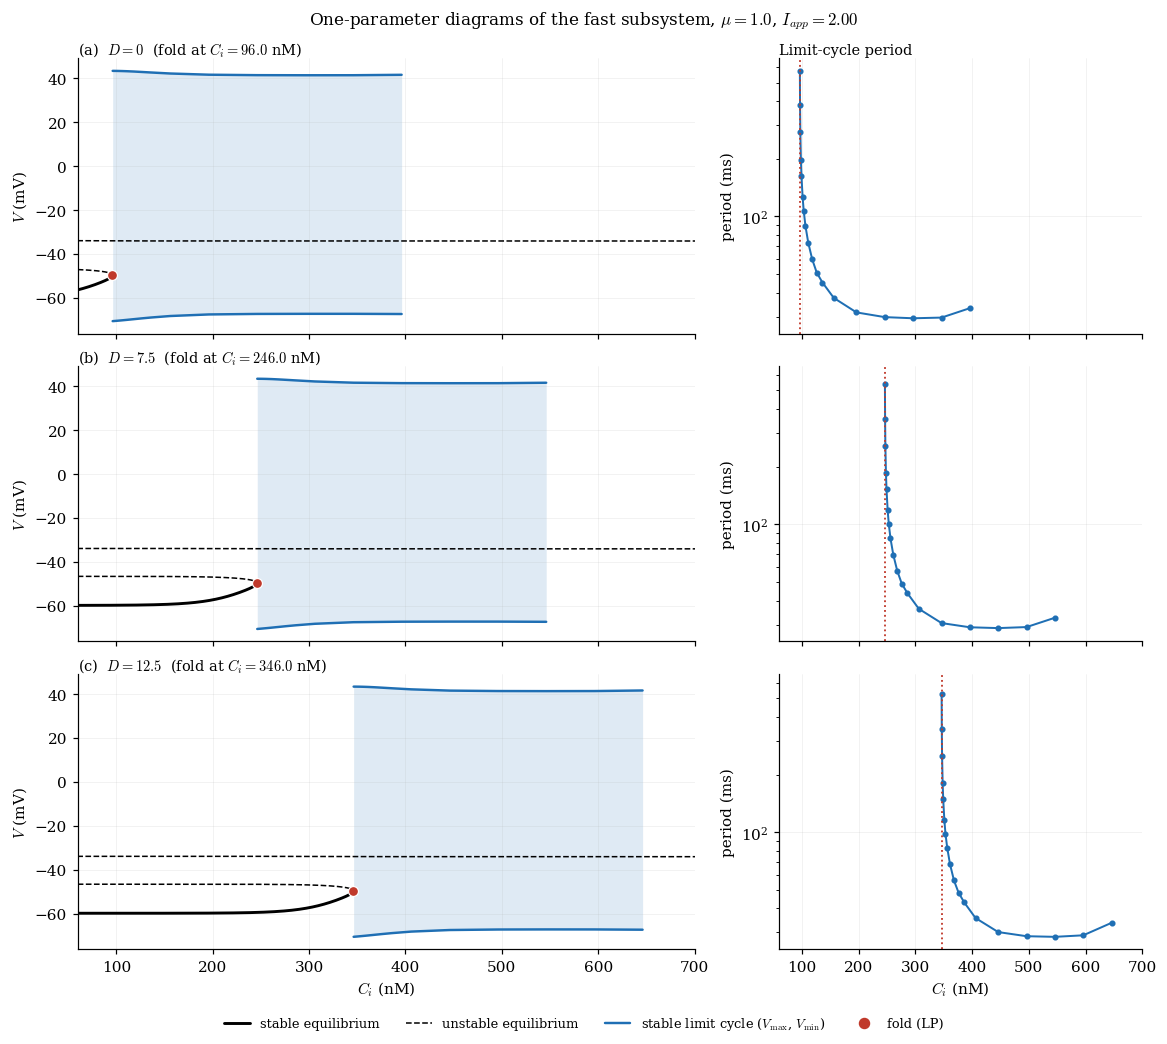

In [10]:
def fast_cycle(x0, Ci, D, Tmax, Vth=-20.0, nspk=4):
    f = lambda t, x: rhs6s(x[0], x[1], x[2], x[3], x[4], x[5], Ci, D, q['Iapp'])
    ev = lambda t, x: x[0]-Vth
    ev.direction = 1
    sol = solve_ivp(f, [0, Tmax], x0, method='LSODA', events=ev, rtol=1e-7, atol=1e-9, max_step=2.0)
    te = sol.t_events[0]
    if len(te) >= 3:
        m = (sol.t >= te[-2]) & (sol.t <= te[-1]); return list(sol.y[:, -1]), (sol.y[0][m].max(), sol.y[0][m].min(), te[-1]-te[-2])
    return list(sol.y[:, -1]), None

def lc_branch(D, Ci_start, Ci_fold, offsets=(0, 30, 60, 100, 150, 200, 250, 300), fine=(40, 30, 22, 15, 10, 7, 5, 3, 2, 1, 0.5, 0.2, 0.0)):
    """Stable limit cycle as Ci decreases towards the fold; returns array of (Ci, Vmax, Vmin, T)."""
    Cis = list(Ci_fold+np.array(sorted(set(offsets+fine), reverse=True)))
    Cis = [c for c in Cis if c <= Ci_start]
    x = list(map(float, steadyv(-30.0, Cis[0]))); rows, Tprev = [], 40.0
    for Ci in Cis:
        x, res = fast_cycle(x, Ci, D, Tmax=min(max(8*Tprev+150, 400.0), 8000.0))
        if res is None: rows.append((Ci, np.nan, np.nan, np.nan)); break
        rows.append((Ci,)+res); Tprev = res[2]
    return np.array(rows)

def slice_data(D):
    curves = [analyse_curve(ln, D) for ln in eq_curves(D)]
    LPd = [s for a in curves for s in a['folds']]; Hd = [s for a in curves for s in a['hopf']]
    Ci_fold = LPd[0]['Ci'] if LPd else CI_RANGE[0]
    return dict(D=D, curves=curves, LP=LPd, H=Hd, Ci_fold=Ci_fold, LCB=lc_branch(D, Ci_fold+300.0, Ci_fold))

t0 = time.time(); SL = [slice_data(D) for D in D_SLICES]
print('limit-cycle sweeps at D = %s: %.0f s' % (', '.join('%g' % D for D in D_SLICES), time.time()-t0))
for s in SL:
    LCB = s['LCB']; ok = ~np.isnan(LCB[:, 1])
    print('D = %4.1f: fold at Ci = %.2f nM; stable cycle exists for Ci >= %.2f nM; period %.0f ms (Ci = %.0f) -> %.0f ms (Ci = %.1f)' %
          (s['D'], s['Ci_fold'], LCB[ok, 0].min(), LCB[ok, 3][0], LCB[ok, 0][0], LCB[ok, 3][-1], LCB[ok, 0][-1]))
    print('         ' + ('=> period grows without bound as Ci -> fold: SNIC (saddle-node on invariant circle)' if LCB[ok, 3][-1] > 5*LCB[ok, 3][0] else '=> period does not diverge at the end of the branch: inspect for a homoclinic or fold of cycles'))

xmax = 50*math.ceil((max(s['Ci_fold'] for s in SL)+330.0)/50.0)
fig, ax = plt.subplots(len(SL), 2, figsize=(10.5, 2.9*len(SL)+0.7), sharex=True, sharey='col', constrained_layout=True,
                       gridspec_kw=dict(width_ratios=[1.7, 1]))
for i, s in enumerate(SL):
    a0, a1 = ax[i]; LCB = s['LCB']; ok = ~np.isnan(LCB[:, 1])
    for a in s['curves']:
        for st, ls, lw in ((True, '-', 1.9), (False, '--', 1.0)):
            a0.plot(np.where(a['stable'] == st, a['Ci'], np.nan), np.where(a['stable'] == st, a['V'], np.nan), color='k', ls=ls, lw=lw)
    a0.fill_between(LCB[ok, 0], LCB[ok, 2], LCB[ok, 1], color=COL['cycle'], alpha=0.14, lw=0)
    a0.plot(LCB[ok, 0], LCB[ok, 1], color=COL['cycle'], lw=1.6); a0.plot(LCB[ok, 0], LCB[ok, 2], color=COL['cycle'], lw=1.6)
    for p in s['LP']: a0.plot(p['Ci'], p['V'], 'o', color=COL['fold'], ms=6.5, mec='white', mew=0.8, zorder=5)
    for p in s['H']:  a0.plot(p['Ci'], p['V'], 's', color=COL['hopf'], ms=6.5, mec='white', mew=0.8, zorder=5)
    a0.set_title(r'(%s)  $D=%g$  (fold at $C_i=%.1f$ nM)' % ('abcdefgh'[i], s['D'], s['Ci_fold']), loc='left', fontsize=9.5, pad=3)
    a0.set_ylabel(r'$V$ (mV)')
    a1.set_yscale('log'); a1.plot(LCB[ok, 0], LCB[ok, 3], 'o-', color=COL['cycle'], ms=3, lw=1.3)
    a1.axvline(s['Ci_fold'], color=COL['fold'], ls=':', lw=1.2); a1.set_ylabel('period (ms)')
    if i == 0: a1.set_title('Limit-cycle period', loc='left', fontsize=9.5, pad=3)
ax[0, 0].set_xlim(CI_RANGE[0], xmax)
for a in ax[-1]: a.set_xlabel(r'$C_i$ (nM)')
handles = [Line2D([], [], color='k', lw=1.9, label='stable equilibrium'), Line2D([], [], color='k', ls='--', lw=1.0, label='unstable equilibrium'),
           Line2D([], [], color=COL['cycle'], lw=1.6, label=r'stable limit cycle ($V_{\max}$, $V_{\min}$)'),
           Line2D([], [], color=COL['fold'], marker='o', ls='', ms=6.5, label='fold (LP)')]
if any(s['H'] for s in SL): handles.append(Line2D([], [], color=COL['hopf'], marker='s', ls='', ms=6.5, label='Hopf (H)'))
fig.legend(handles=handles, loc='outside lower center', ncol=len(handles))
fig.suptitle(r'One-parameter diagrams of the fast subsystem, $\mu=%.1f$, $I_{app}=%.2f$' % (q['mu'], q['Iapp']), fontsize=11)
fig.savefig('bifurcation_1d_slices.pdf', dpi=300, bbox_inches='tight'); plt.show()


## 5. Two-parameter bifurcation diagram in $(C_i, D)$
Fold and Hopf curves come from the scan in Section 3. The end of the stable limit cycle is found at four values of $D$ with the same sweep as in Section 4 and drawn as markers; where it coincides with the fold curve and the period diverges, the fold is a SNIC. The burst orbit (the slow $(C_i, D)$ trajectory from Section 2) is overlaid, so termination and re-initiation can be read off where it crosses the curves. The three values of $D$ used in Section 4 are drawn as dashed horizontal lines.

cycle-end sweeps: 9 s
  D =  0.0: stable cycle down to Ci = 96.22 nM (fold 96.02 nM), period 33 -> 575 ms
  D = 10.0: stable cycle down to Ci = 296.23 nM (fold 296.03 nM), period 33 -> 533 ms
  D = 20.0: stable cycle down to Ci = 496.23 nM (fold 496.03 nM), period 32 -> 513 ms
  D = 30.0: stable cycle down to Ci = 696.23 nM (fold 696.03 nM), period 32 -> 499 ms


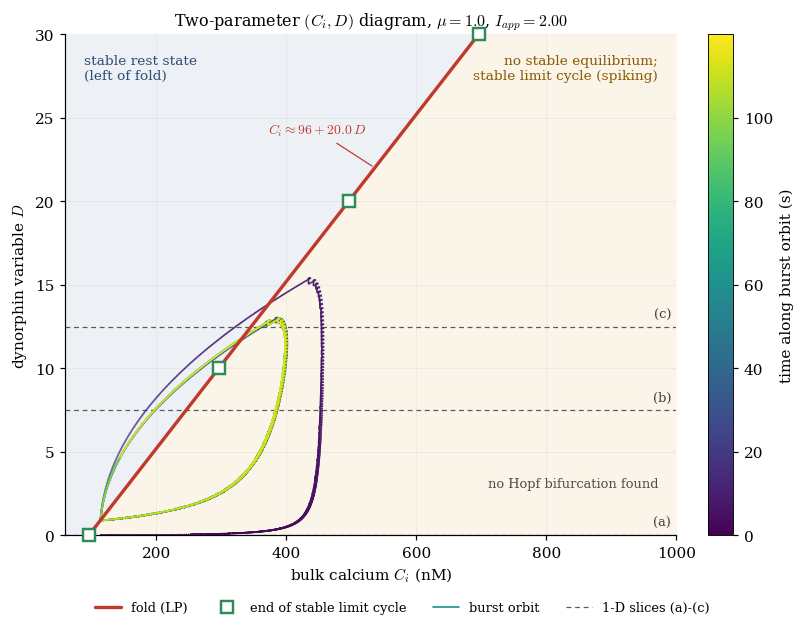

In [11]:
def link_curves(pts, tol=60.0):
    """Join points found on adjacent D rows into curves (nearest Ci within tol)."""
    curves = []
    for s in sorted(pts, key=lambda s: s['D']):
        best = min(curves, key=lambda c: abs(c[-1]['Ci']-s['Ci'])+1e6*(c[-1]['D'] == s['D']), default=None)
        if best is not None and abs(best[-1]['Ci']-s['Ci']) < tol and best[-1]['D'] != s['D']: best.append(s)
        else: curves.append([s])
    return curves

t0 = time.time(); LC_END = []
for D in (0.0, D_MAX/3, 2*D_MAX/3, D_MAX):
    lps = [s for ln in eq_curves(D) for s in analyse_curve(ln, D)['folds']]
    if not lps: continue
    Cf = lps[0]['Ci']; B = lc_branch(D, Cf+250.0, Cf); good = ~np.isnan(B[:, 1])
    if good.any(): LC_END.append((D, B[good, 0].min(), B[good, 3][-1], B[good, 3][0], Cf))
print('cycle-end sweeps: %.0f s' % (time.time()-t0))
for D, Cend, Tend, T0, Cf in LC_END: print('  D = %4.1f: stable cycle down to Ci = %.2f nM (fold %.2f nM), period %.0f -> %.0f ms' % (D, Cend, Cf, T0, Tend))


main = max(link_curves(LP), key=len)                       # the fold curve, ordered by D
Cf_c = np.array([s['Ci'] for s in main]); Df_c = np.array([s['D'] for s in main])
XMAX = min(CI_RANGE[1], 20*D_MAX+400); XMIN = CI_RANGE[0]

fig, ax = plt.subplots(figsize=(7.2, 5.6), constrained_layout=True)
ax.fill_betweenx(Df_c, XMIN, Cf_c, color='#3b6ea5', alpha=0.09, lw=0)
ax.fill_betweenx(Df_c, Cf_c, XMAX, color='#e0a030', alpha=0.10, lw=0)
ax.text(0.03, 0.96, 'stable rest state\n(left of fold)', transform=ax.transAxes, va='top', fontsize=9, color='#2b4d77')
ax.text(0.97, 0.96, 'no stable equilibrium;\nstable limit cycle (spiking)', transform=ax.transAxes, va='top', ha='right', fontsize=9, color='#8a5a00')

for c in link_curves(HP): ax.plot([s['Ci'] for s in c], [s['D'] for s in c], '-', color=COL['hopf'], lw=2.0)
ax.plot(Cf_c, Df_c, '-', color=COL['fold'], lw=2.2, zorder=4)

for i, d in enumerate(D_SLICES):
    ax.axhline(d, color='0.35', ls=(0, (4, 3)), lw=0.8, zorder=1)
    ax.text(XMAX-8, d+0.35, '(%s)' % 'abcdefgh'[i], ha='right', va='bottom', fontsize=8.5, color='0.25')

if LC_END: ax.plot([e[1] for e in LC_END], [e[0] for e in LC_END], 's', ms=7.5, mfc='white', mec=COL['end'], mew=1.6, zorder=5, clip_on=False)

pts = np.c_[R['Ci'][::10], R['D'][::10]]; tsub = R['t'][::10]/1000.0
seg = np.stack([pts[:-1], pts[1:]], axis=1)
lc = LineCollection(seg, cmap='viridis', norm=plt.Normalize(0, tsub[-1]), linewidth=1.1, zorder=3)
lc.set_array(0.5*(tsub[:-1]+tsub[1:])); ax.add_collection(lc)
cb = fig.colorbar(lc, ax=ax, pad=0.02, fraction=0.045); cb.set_label('time along burst orbit (s)'); cb.outline.set_linewidth(0.6)

k = int(0.75*(len(Df_c)-1))
ax.annotate(r'$C_i\approx %.0f+%.1f\,D$' % (FOLD_FIT[1], FOLD_FIT[0]), xy=(Cf_c[k], Df_c[k]), xytext=(-70, 22), textcoords='offset points',
            fontsize=9, color=COL['fold'], arrowprops=dict(arrowstyle='-', color=COL['fold'], lw=0.8))
if not HP: ax.text(0.97, 0.09, 'no Hopf bifurcation found', transform=ax.transAxes, ha='right', va='bottom', fontsize=8.5, color='0.3')

ax.set_xlim(XMIN, XMAX); ax.set_ylim(0, D_MAX); ax.set_xlabel(r'bulk calcium $C_i$ (nM)'); ax.set_ylabel(r'dynorphin variable $D$')
ax.set_title(r'Two-parameter $(C_i, D)$ diagram, $\mu=%.1f$, $I_{app}=%.2f$' % (q['mu'], q['Iapp']), fontsize=10.5)
handles = [Line2D([], [], color=COL['fold'], lw=2.2, label='fold (LP)')]
if HP: handles.append(Line2D([], [], color=COL['hopf'], lw=2.0, label='Hopf (H)'))
if LC_END: handles.append(Line2D([], [], color=COL['end'], marker='s', ls='', mfc='white', mew=1.6, ms=7.5, label='end of stable limit cycle'))
handles += [Line2D([], [], color=plt.get_cmap('viridis')(0.5), lw=1.1, label='burst orbit'), Line2D([], [], color='0.35', ls=(0, (4, 3)), lw=0.8, label='1-D slices (a)-(c)')]
fig.legend(handles=handles, loc='outside lower center', ncol=len(handles))
fig.savefig('bifurcation_2d.pdf', dpi=300, bbox_inches='tight'); plt.show()
